<a href="https://colab.research.google.com/github/wonjun605/Digital-Image-Processing/blob/main/ch7_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


(256, 256, 3)


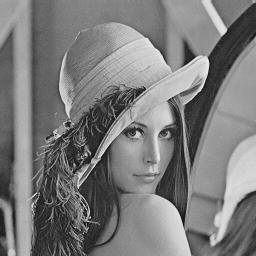

In [2]:
Img = cv2.imread('/content/gdrive/My Drive/ColabIP26/Images/lena256.jpg')
RGB_Img = cv2.cvtColor(Img, cv2.COLOR_BGR2RGB)

gImg= cv2.cvtColor(RGB_Img, cv2.COLOR_RGB2GRAY)
print(Img.shape)
cv2_imshow(gImg)

In [3]:
height, width = gImg.shape
print(height, width)

256 256


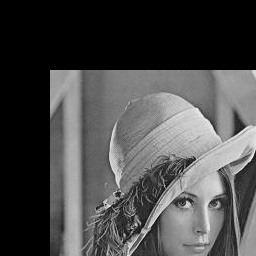

In [5]:
T = np.float32([[1,0,50],[0,1,70]])
outImg = cv2.warpAffine(gImg, T, (width, height))
cv2_imshow(outImg)

[[  0.76604444   0.64278761 -52.33050276]
 [ -0.64278761   0.76604444 112.22312532]]


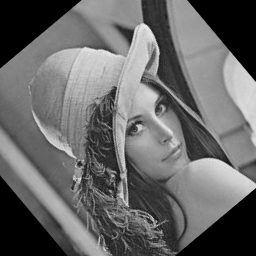

In [8]:
R = cv2.getRotationMatrix2D((width/2, height/2), 40, 1)
print(R)
outImg = cv2.warpAffine(gImg, R, (width, height))
cv2_imshow(outImg)

[[ 0.76604444  0.64278761  0.        ]
 [-0.64278761  0.76604444  0.        ]]


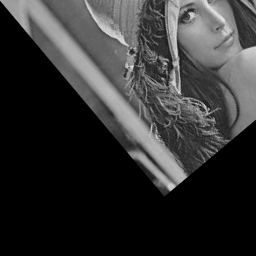

In [9]:
R = cv2.getRotationMatrix2D((0,0), 40, 1)
print(R)
outImg = cv2.warpAffine(gImg, R, (width, height))
cv2_imshow(outImg)

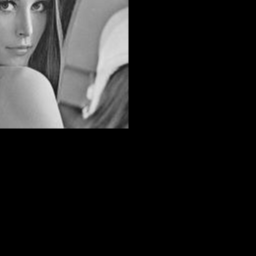

In [21]:
T1 = np.float32([[1,0,-(width-1)/2],[0,1,-(height-1)/2]])
outImg = cv2.warpAffine(gImg, T1, (width, height))
cv2_imshow(outImg)

[[ 0.76604444  0.64278761  0.        ]
 [-0.64278761  0.76604444  0.        ]]


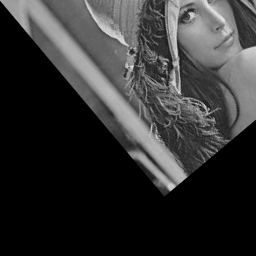

In [22]:
R = cv2.getRotationMatrix2D((0,0), 40, 1)
print(R)
outImg1 = cv2.warpAffine(gImg, R, (width, height))
cv2_imshow(outImg1)

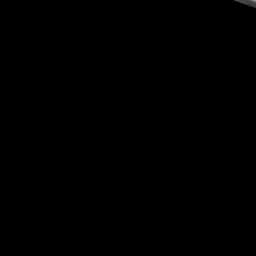

In [23]:
T2 = np.float32([[1,2,-(width-1)/2],[0,1,-(height-1)/2]])
outImg2 = cv2.warpAffine(outImg1, T2, (width, height))
cv2_imshow(outImg2)

[[  0.76604444   0.64278764 -52.1261    ]
 [ -0.64278764   0.76604444 111.78476   ]
 [  0.           0.           1.        ]]


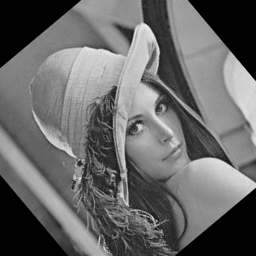

In [25]:
T1 = np.float32([[1, 0, -(width-1)/2], [0, 1, -(height-1)/2], [0, 0, 1]])
R = cv2.getRotationMatrix2D((0,0), 40, 1)
R1 = np.float32([[R[0,0], R[0,1], R[0,2]], [R[1,0], R[1,1], R[1,2]], [0, 0, 1]])
T2 = np.float32([[1, 0, (width-1)/2], [0, 1, (height-1)/2], [0, 0, 1]])

M1 = np.dot(R1, T1)
M2 = np.dot(T2, M1)
print(M2)

# cv2.warpAffine은 2x3 행렬을 입력받으므로, 3x3 행렬 M2에서 상단 2행만 슬라이싱하여 사용합니다.
outImg = cv2.warpAffine(gImg, M2[:2, :], (width, height))
cv2_imshow(outImg)